# Level 2: House Price Prediction (Regression)

Predict median home value in Boston-area census tracts with Linear Regression, a Decision Tree and a Random Forest, and compare their performance.

**Tools:** Python, pandas, scikit-learn, matplotlib

## 0. Setup

In [14]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeRegressor

## 1. Data and source

The dataset is the Boston Housing data from StatLib (Carnegie Mellon), compiled by Harrison and Rubinfeld (1978). It has 506 rows, and each row is a census tract, not a single house. The target is `MEDV`, the median value of owner-occupied homes in $1000s. There are 13 features, and the task is to predict `MEDV`.


### Load and rebuild the raw file

The raw StatLib file stores each record across two lines, so it is rebuilt into a 506 x 14 table.

In [15]:
cols = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS",
        "RAD","TAX","PTRATIO","B","LSTAT","MEDV"]

raw = pd.read_csv("boston.txt", sep=r"\s+", skiprows=22, header=None)
print(raw.head(4))   # check before continuing

odd = raw.values[::2, :]        # lines with 11 values
even = raw.values[1::2, :3]     # lines with the last 3 values
df = pd.DataFrame(np.hstack([odd, even]), columns=cols)

print(df.shape)      # expect (506, 14)
print(df.iloc[0])    # CRIM 0.00632, MEDV 24.0
df.to_csv("boston_housing.csv", index=False)

          0      1      2    3      4      5     6       7    8      9     10
0    0.00632  18.00   2.31  0.0  0.538  6.575  65.2  4.0900  1.0  296.0  15.3
1  396.90000   4.98  24.00  NaN    NaN    NaN   NaN     NaN  NaN    NaN   NaN
2    0.02731   0.00   7.07  0.0  0.469  6.421  78.9  4.9671  2.0  242.0  17.8
3  396.90000   9.14  21.60  NaN    NaN    NaN   NaN     NaN  NaN    NaN   NaN
(506, 14)
CRIM         0.00632
ZN          18.00000
INDUS        2.31000
CHAS         0.00000
NOX          0.53800
RM           6.57500
AGE         65.20000
DIS          4.09000
RAD          1.00000
TAX        296.00000
PTRATIO     15.30000
B          396.90000
LSTAT        4.98000
MEDV        24.00000
Name: 0, dtype: float64


### Quick checks

In [16]:
print(df.head(6))


      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0  296.0   
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0  242.0   
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0  242.0   
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0  222.0   
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0  222.0   
5  0.02985   0.0   2.18   0.0  0.458  6.430  58.7  6.0622  3.0  222.0   

   PTRATIO       B  LSTAT  MEDV  
0     15.3  396.90   4.98  24.0  
1     17.8  396.90   9.14  21.6  
2     17.8  392.83   4.03  34.7  
3     18.7  394.63   2.94  33.4  
4     18.7  396.90   5.33  36.2  
5     18.7  394.12   5.21  28.7  


In [17]:
print(df.isna().sum())

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


## 2. Method

The raw file stores each record across two lines, so I rebuilt it into a 506 x 14 table. I dropped `B` (see section 6), which left 12 features. I split the data 80/20 (404 train, 102 test) with `random_state=42`. A baseline that predicts the training mean was compared with Linear Regression, a Decision Tree and a Random Forest. I measured MSE, RMSE and R² on the test set. I also ran 5-fold cross-validation with shuffling, because a single 102-row test set is small.

### Train/test split

In [18]:
df = pd.read_csv("boston_housing.csv")

X = df.drop(columns=["MEDV", "B"])   # B dropped for the main run
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(404, 12) (102, 12) (404,) (102,)


### Baseline and Linear Regression

In [19]:
def evaluate(model, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    print(f"{name}: MSE={mse:.2f}  RMSE={np.sqrt(mse):.2f}  R2={r2_score(y_test, pred):.3f}")

evaluate(DummyRegressor(strategy="mean"), "Baseline")
evaluate(LinearRegression(), "Linear Regression")

Baseline: MSE=75.05  RMSE=8.66  R2=-0.023
Linear Regression: MSE=22.78  RMSE=4.77  R2=0.689


### Decision Tree and Random Forest

The training scores check for overfitting.

In [20]:
evaluate(DecisionTreeRegressor(random_state=42), "Decision Tree")
evaluate(RandomForestRegressor(random_state=42), "Random Forest")

for name, m in [("Tree", DecisionTreeRegressor(random_state=42)),
                   ("Forest", RandomForestRegressor(random_state=42))]:
       m.fit(X_train, y_train)
       print(name, "train R2:", round(m.score(X_train, y_train), 3),
             "test R2:", round(m.score(X_test, y_test), 3))

Decision Tree: MSE=8.98  RMSE=3.00  R2=0.878


Random Forest: MSE=8.01  RMSE=2.83  R2=0.891
Tree train R2: 1.0 test R2: 0.878
Forest train R2: 0.977 test R2: 0.891


### Cross-validation

Unshuffled first, then shuffled. The shuffled run is the main result.

In [21]:
# Unshuffled 5-fold CV (file is ordered by tract, so folds hold out whole areas)
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5, scoring="r2")
    print(f"{name}: mean R2={scores.mean():.3f}  std={scores.std():.3f}")

Linear Regression: mean R2=0.377  std=0.336
Decision Tree: mean R2=0.053  std=0.926
Random Forest: mean R2=0.628  std=0.201


In [22]:
# Shuffled 5-fold CV (main comparison)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=kf, scoring="r2")
    print(f"{name}: mean R2={scores.mean():.3f}  std={scores.std():.3f}")

Linear Regression: mean R2=0.712  std=0.031
Decision Tree: mean R2=0.729  std=0.131
Random Forest: mean R2=0.871  std=0.031


### Charts

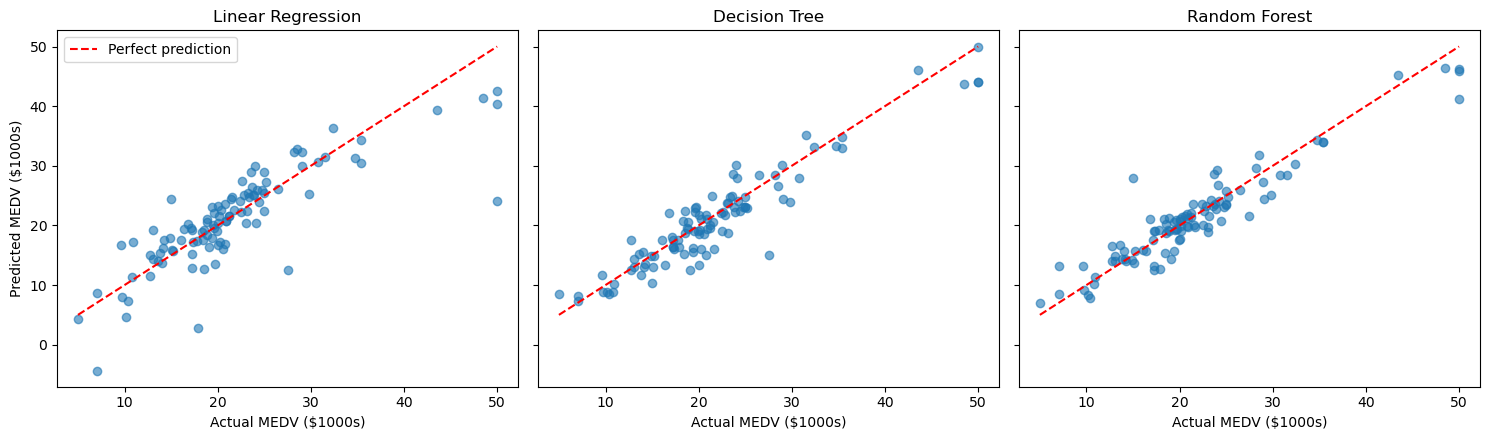

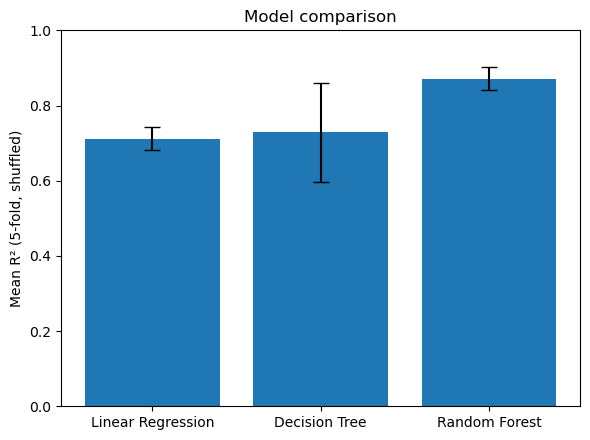

In [23]:
# Chart 1: actual vs predicted on the test set
os.makedirs("images", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
lims = [y.min(), y.max()]

for ax, (name, m) in zip(axes, models.items()):
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(name)
    ax.set_xlabel("Actual MEDV ($1000s)")
axes[0].set_ylabel("Predicted MEDV ($1000s)")
axes[0].legend()
plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150)
plt.show()

# Chart 2: shuffled 5-fold CV mean R2 with std error bars
kf = KFold(n_splits=5, shuffle=True, random_state=42)
means, stds = [], []
for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=kf, scoring="r2")
    means.append(scores.mean())
    stds.append(scores.std())

plt.figure(figsize=(6, 4.5))
plt.bar(models.keys(), means, yerr=stds, capsize=6)
plt.ylabel("Mean R² (5-fold, shuffled)")
plt.title("Model comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig("images/cv_comparison.png", dpi=150)
plt.show()

## 3. Results

In [24]:
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    cv = cross_val_score(m, X, y, cv=kf, scoring="r2")
    rows.append({
        "Model": name,
        "MSE": round(mse, 2),
        "RMSE": round(np.sqrt(mse), 2),
        "R2 (test)": round(r2_score(y_test, pred), 3),
        "CV R2 mean": round(cv.mean(), 3),
        "CV R2 std": round(cv.std(), 3),
    })

results = pd.DataFrame(rows).set_index("Model")
print(results)
results.to_csv("results_table.csv")

                     MSE  RMSE  R2 (test)  CV R2 mean  CV R2 std
Model                                                           
Baseline (mean)    75.05  8.66     -0.023      -0.011      0.007
Linear Regression  22.78  4.77      0.689       0.712      0.031
Decision Tree       8.98  3.00      0.878       0.729      0.131
Random Forest       8.01  2.83      0.891       0.871      0.031


| Model | MSE | RMSE | R² (test) | CV R² mean | CV R² std |
|---|---|---|---|---|---|
| Baseline (mean) | 75.05 | 8.66 | -0.023 | -0.011 | 0.007 |
| Linear Regression | 22.78 | 4.77 | 0.689 | 0.712 | 0.031 |
| Decision Tree | 8.98 | 3.00 | 0.878 | 0.729 | 0.131 |
| Random Forest | 8.01 | 2.83 | 0.891 | 0.871 | 0.031 |

The CV columns give the mean and standard deviation of R² across five shuffled folds. RMSE is in $1000s, so the forest's typical error is about $2,830.

## 4. Findings

The Random Forest performed best on both the single split (R² 0.891) and cross-validation (mean 0.871, std 0.031). The Decision Tree overfits: its training R² is 1.0, its test R² is 0.878, and its cross-validated mean drops to 0.729 with a std of 0.131. On the single split the tree and forest were too close to rank, so I treat the shuffled cross-validation as the main result. Linear Regression is stable (std 0.031) but about 0.16 R² below the forest, which suggests nonlinear relationships in the data.

## 5. Limitations

- Without shuffling, 5-fold CV scored the forest only 0.628 (tree 0.053, linear 0.377). The file is ordered by tract, so unshuffled folds test on unfamiliar areas, and all models do much worse there.
- `MEDV` is capped at 50.0, so the most expensive tracts are not represented accurately. **(Fill in the count from the check above: ___ tracts.)**
- The data describes 1970s Boston. The results should not be used to draw conclusions about people or neighbourhoods today.

## 6. Ethical note

Column `B` is derived from the proportion of Black residents, and its authors assumed that racial segregation raises house prices. scikit-learn removed this dataset for fairness reasons. I excluded `B` from the models and kept the other features.